# Context-Aware Prediction of Electricity Use in the Vrijhof Building
**Course:** Introduction to Data Science — VU Minor Data Science  
**Case:** Vrijhof building, University of Twente  
**Analysis period:** 1 September 2025 – 31 August 2026  
**Target:** `electricity_kWh`

## 1. Introduction and research question
**To what extent can contextual factors predict hourly electricity use in Vrijhof, and can prediction errors identify unusual consumption patterns?**

We describe hourly consumption, compare Multiple Linear Regression (MLR) with a same-hour-previous-day baseline, examine the predictive contribution of four context groups, and investigate the largest prediction errors.

**Preselected primary success criterion:** contextual MAE < previous-day baseline MAE. MAE measures the average absolute error directly in kWh. RMSE and R² provide supplementary information; they do not replace this criterion.

Run all cells from top to bottom with `final_dataset.csv` in the same folder, using that folder as the working directory. Required packages: pandas, numpy, matplotlib, scikit-learn and Jupyter. The saved outputs were produced by executing the analysis cells in order.

## Use of an LLM
The research question, predictors, chronological split and success criterion follow our project analysis plan. LLM assistance was used to help implement the code and refine its presentation. The methodological decisions are explained in the relevant sections below.

For important steps, the notebook distinguishes between:
- **What we found:** observations from the data or analysis;
- **Decision:** the approach used and why;
- **Check:** how the result was verified.

Selected plotting sections also include a short **LLM support** note about practical implementation details. These notes describe the assistance used in preparing this notebook; they are not verbatim records of earlier prompts.


## 2. Imports and data loading
Load `final_dataset.csv` once, parse timestamps and sort chronologically. All later sections reuse this dataframe.

In [1]:
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

data_path = Path("final_dataset.csv")
df = pd.read_csv(data_path, parse_dates=["timestamp"])
df = df.sort_values("timestamp").reset_index(drop=True)

# Save the current figures for use on the poster.
figure_folder = Path("figures")
figure_folder.mkdir(exist_ok=True)

## 3. Dataset overview and preparation summary
Cleaning and integration are documented in the preparation notebook. The expected prepared dataset has 8,757 observations and 13 variables, unique timestamps and 26 missing previous-day baseline values. The two two-hour timestamp gaps follow the preparation decisions and daylight-saving transition.

Inspect missing values once. Verify the baseline with a timestamp-based merge, matching the same local clock hour on the previous day; missing values are retained and `shift(24)` is avoided.

In [2]:
print("Dataset shape:", df.shape)
print("Period:", df["timestamp"].min(), "to", df["timestamp"].max())
display(df.head())
print("Column types:")
print(df.dtypes)
print("Missing values:")
print(df.isna().sum())

Dataset shape: (8757, 13)
Period: 2025-09-01 01:00:00 to 2026-08-31 23:00:00


,timestamp,electricity_kWh,outdoor_temperature,solar_radiation,precipitation_mm,relative_humidity,hour_of_day,day_of_week,academic_period,assessment_period,UT_closed,building_open,electricity_previous_day_same_hour
0,2025-09-01 01:00:00,29,18.0,0,9.8,99,1,Monday,Q1,0,0,0,NaN
1,2025-09-01 02:00:00,28,17.6,0,6.0,99,2,Monday,Q1,0,0,0,NaN
2,2025-09-01 03:00:00,27,16.6,0,2.2,97,3,Monday,Q1,0,0,0,NaN
3,2025-09-01 04:00:00,29,15.8,0,1.1,96,4,Monday,Q1,0,0,0,NaN
4,2025-09-01 05:00:00,30,15.6,0,2.0,98,5,Monday,Q1,0,0,0,NaN


Column types:
timestamp                             datetime64[us]
electricity_kWh                                int64
outdoor_temperature                          float64
solar_radiation                                int64
precipitation_mm                             float64
relative_humidity                              int64
hour_of_day                                    int64
day_of_week                                      str
academic_period                                  str
assessment_period                              int64
UT_closed                                      int64
building_open                                  int64
electricity_previous_day_same_hour           float64
dtype: object
Missing values:
timestamp                              0
electricity_kWh                        0
outdoor_temperature                    0
solar_radiation                        0
precipitation_mm                       0
relative_humidity                      0
hour_of_day          

In [3]:
print("Missing timestamps:", df["timestamp"].isna().sum())
print("Duplicate timestamps:", df["timestamp"].duplicated().sum())
print("Time gaps between consecutive observations:")
print(df["timestamp"].diff().value_counts())

Missing timestamps: 0
Duplicate timestamps: 0
Time gaps between consecutive observations:
timestamp
0 days 01:00:00    8754
0 days 02:00:00       2
Name: count, dtype: int64


In [4]:
# Match each hour with the same clock hour on the previous day.
baseline = "electricity_previous_day_same_hour"
previous_day = df[["timestamp", "electricity_kWh"]].copy()
previous_day["timestamp"] = previous_day["timestamp"] + pd.Timedelta(days=1)
previous_day = previous_day.rename(columns={"electricity_kWh": "baseline_check"})

baseline_check = pd.merge(df[["timestamp", baseline]], previous_day, on="timestamp", how="left")
same_value = baseline_check[baseline] == baseline_check["baseline_check"]
both_missing = baseline_check[baseline].isna() & baseline_check["baseline_check"].isna()
mismatches = baseline_check.loc[~(same_value | both_missing)]
print("Baseline mismatches:", len(mismatches))
if len(mismatches) > 0:
    display(mismatches)
    raise ValueError("Check the baseline before continuing.")


Baseline mismatches: 0


## 4. Descriptive analysis
Use whole-year means to compare weekdays with weekends and show individual weekday-hour patterns. These summaries describe the data; they are not test performance estimates and are not used to select predictors.

**LLM support:** practical help with axis labels, weekday ordering and figure spacing.

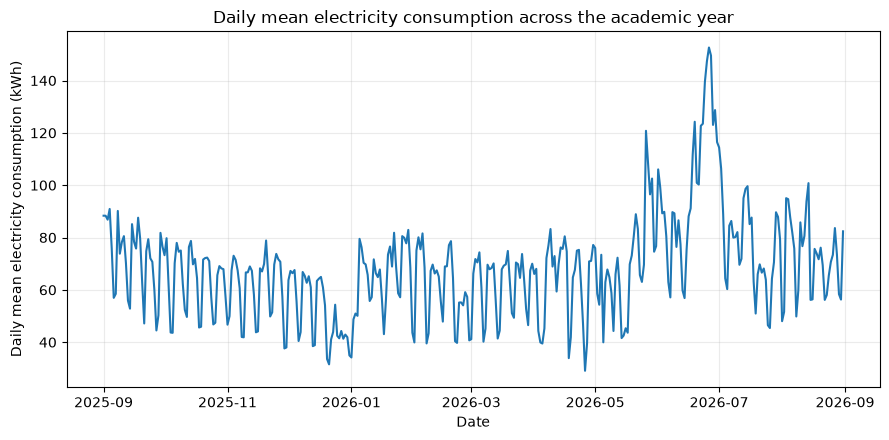

In [5]:
# Daily mean electricity consumption across the academic year
daily_profile = df.set_index("timestamp").resample("D")["electricity_kWh"].mean()

plt.figure(figsize=(9, 4.5))
plt.plot(daily_profile.index, daily_profile.values)
plt.xlabel("Date")
plt.ylabel("Daily mean electricity consumption (kWh)")
plt.title("Daily mean electricity consumption across the academic year")
plt.grid(alpha=0.25)
plt.tight_layout()
plt.savefig(figure_folder / "daily_electricity_academic_year.png", dpi=300, bbox_inches="tight")
plt.show()


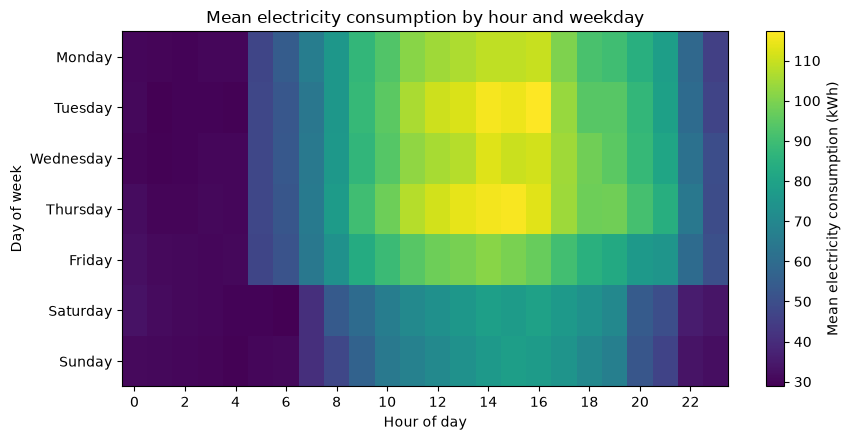

In [6]:
weekday_order = ["Monday", "Tuesday", "Wednesday", "Thursday", "Friday", "Saturday", "Sunday"]

heatmap_data = df.pivot_table(
    index="day_of_week", columns="hour_of_day", values="electricity_kWh", aggfunc="mean"
).reindex(weekday_order).reindex(columns=range(24))

plt.figure(figsize=(9, 4.5))
plt.imshow(heatmap_data, aspect="auto")
plt.colorbar(label="Mean electricity consumption (kWh)")
plt.xticks(range(0, 24, 2), range(0, 24, 2))
plt.yticks(range(7), weekday_order)
plt.xlabel("Hour of day")
plt.ylabel("Day of week")
plt.title("Mean electricity consumption by hour and weekday")
plt.tight_layout()
plt.savefig(figure_folder / "hour_weekday_heatmap.png", dpi=300, bbox_inches="tight")
plt.show()


### Interpretation of the descriptive figures
Average consumption is close to 30 kWh overnight and rises during the day. The weekday mean reaches roughly 110 kWh, while the weekend mean peaks around 78 kWh. The heatmap shows how this pattern varies across weekdays. These are associations in the observed year; they do not establish that opening hours or occupancy caused the differences.

## 5. Model setup
The target is `electricity_kWh`. The previous-day baseline is **not** a contextual predictor.

| Group | Predictors |
|---|---|
| Weather | outdoor_temperature, solar_radiation, precipitation_mm, relative_humidity |
| Time | hour_of_day, day_of_week |
| Academic | academic_period, assessment_period, UT_closed |
| Opening status | building_open |

Use the first 80% of sorted rows for training and the final 20% for testing. `OneHotEncoder(handle_unknown="ignore")` learns categories from training data only. Unseen test categories receive zeros for that feature's encoded columns. The Pipeline fits preprocessing and regression together, only on training rows. Numeric predictors pass through unchanged.

This evaluates contextual prediction with observed weather. It is not a forecast using weather forecasts. The baseline uses the previous day's observed consumption, including earlier test-period observations when available; it is a rolling hourly benchmark.

### Analysis decision

**What we found**  
The data are hourly observations in time order. The project specifies four context groups and a previous-day benchmark. A chronological 80/20 split evaluates the model on later observations.

**Decision**  
Define the groups once. Treat hour_of_day, day_of_week and academic_period as categorical; weather and the binary indicators pass through as numeric. Use a ColumnTransformer and LinearRegression inside a Pipeline.

**Check**  
Check that predictors and target have no missing values and that the final training timestamp is earlier than the first test timestamp. Display the row counts and date ranges. The baseline column is absent from model_features.

In [7]:
target = "electricity_kWh"
weather_features = ["outdoor_temperature", "solar_radiation", "precipitation_mm", "relative_humidity"]
time_features = ["hour_of_day", "day_of_week"]
academic_features = ["academic_period", "assessment_period", "UT_closed"]
opening_features = ["building_open"]

model_features = weather_features + time_features + academic_features + opening_features
categorical_features = time_features + ["academic_period"]
numeric_features = weather_features + ["assessment_period", "UT_closed", "building_open"]


In [8]:
# Earlier observations train the model; later observations test it.
split_index = int(0.8 * len(df))
train = df.iloc[:split_index].copy()
test = df.iloc[split_index:].copy()

X_train = train[model_features]
y_train = train[target]
X_test = test[model_features]

print("Train:", len(train), "rows,", train["timestamp"].min(), "to", train["timestamp"].max())
print("Test:", len(test), "rows,", test["timestamp"].min(), "to", test["timestamp"].max())

Train: 7005 rows, 2025-09-01 01:00:00 to 2026-06-19 23:00:00
Test: 1752 rows, 2026-06-20 00:00:00 to 2026-08-31 23:00:00


In [9]:
# Check academic categories that the model has not seen during training.
train_periods = train["academic_period"].unique()
unseen_periods = test.loc[~test["academic_period"].isin(train_periods), "academic_period"]
print("Test academic categories absent from training:")
print(unseen_periods.value_counts())
print("Coverage:", len(unseen_periods), "of", len(test), "test hours")

Test academic categories absent from training:
academic_period
summer_period       1344
outside_calendar      24
Name: count, dtype: int64
Coverage: 1368 of 1752 test hours


`handle_unknown="ignore"` encodes unseen categories with zeros for their academic-period columns. The model still uses the other predictors, but has not learned a separate effect for these academic periods. This is a limitation of the chronological holdout, not a reason to fit the encoder on test data.

In [10]:
preprocessor = ColumnTransformer([
    ("categorical", OneHotEncoder(handle_unknown="ignore"), categorical_features),
    ("numeric", "passthrough", numeric_features)
])
model = Pipeline([("preprocessing", preprocessor), ("regression", LinearRegression())])


## 6. Contextual model vs previous-day baseline
Fit the full contextual model once. Store all test predictions in `results` and compare both methods on the same rows with an available baseline (`evaluation`). Keep those predictions for residual analysis.

MAE measures average absolute error in kWh; RMSE places more weight on large errors; R² compares squared error with a constant test-mean prediction.

**LLM support:** practical help adding values above bars and the reference line to the scatterplot.

In [11]:
model.fit(X_train, y_train)
contextual_predictions = model.predict(X_test)
results = test[["timestamp", target, baseline]].copy()
results["contextual_prediction"] = contextual_predictions
evaluation = results.dropna(subset=[baseline]).copy()
print("Test rows:", len(results), "| Common evaluation rows:", len(evaluation))

Test rows: 1752 | Common evaluation rows: 1752


In [12]:
metric_rows = []
for name, column in [("Contextual MLR", "contextual_prediction"), ("Previous-day baseline", baseline)]:
    actual = evaluation[target]
    predicted = evaluation[column]
    metric_rows.append({
        "Model": name,
        "MAE": mean_absolute_error(actual, predicted),
        "RMSE": np.sqrt(mean_squared_error(actual, predicted)),
        "R²": r2_score(actual, predicted)
    })

metrics = pd.DataFrame(metric_rows).set_index("Model")
display(metrics.round(3))


,MAE,RMSE,R²
Model,,,
Contextual MLR,18.155,25.92,0.603
Previous-day baseline,14.609,21.73,0.721


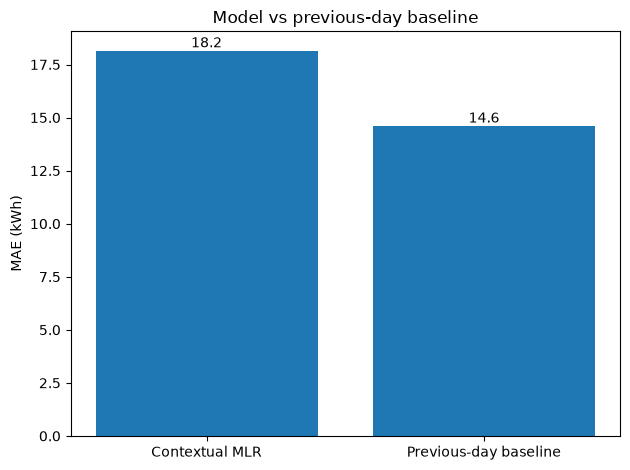

In [13]:
plt.figure()
bars = plt.bar(metrics.index, metrics["MAE"])
plt.ylabel("MAE (kWh)")
plt.title("Model vs previous-day baseline")
plt.bar_label(bars, fmt="%.1f")
plt.tight_layout()
plt.savefig(figure_folder / "mae_model_vs_baseline.png", dpi=300, bbox_inches="tight")
plt.show()


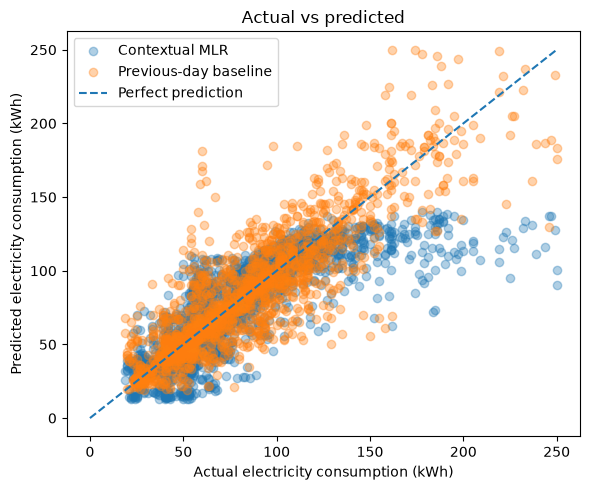

In [14]:
plt.figure(figsize=(6, 5))
plt.scatter(evaluation[target], evaluation["contextual_prediction"], alpha=0.35, label="Contextual MLR")
plt.scatter(evaluation[target], evaluation[baseline], alpha=0.35, label="Previous-day baseline")

limit = max(
    evaluation[target].max(),
    evaluation["contextual_prediction"].max(),
    evaluation[baseline].max()
)
plt.plot([0, limit], [0, limit], "--", label="Perfect prediction")
plt.xlabel("Actual electricity consumption (kWh)")
plt.ylabel("Predicted electricity consumption (kWh)")
plt.title("Actual vs predicted")
plt.legend()
plt.tight_layout()
plt.savefig(figure_folder / "actual_vs_predicted_model_and_baseline.png", dpi=300, bbox_inches="tight")
plt.show()


## 7. Success criterion
The preselected criterion is strictly **contextual MAE < baseline MAE**. Compare the unrounded MAE values; RMSE and R² remain supplementary metrics from the table above. An unfavourable result does not justify changing the method or criterion.

In [15]:
contextual_mae = metrics.loc["Contextual MLR", "MAE"]
baseline_mae = metrics.loc["Previous-day baseline", "MAE"]

print("Contextual MAE:", round(contextual_mae, 3), "kWh")
print("Baseline MAE:", round(baseline_mae, 3), "kWh")
if contextual_mae < baseline_mae:
    print("Primary success criterion: met.")
else:
    print("Primary success criterion: not met.")

Contextual MAE: 18.155 kWh
Baseline MAE: 14.609 kWh
Primary success criterion: not met.


## 8. Predictive contribution of context groups
Remove one group at a time and fit four reduced models on the existing training rows. Reuse the full-model MAE and score every ablation on the same evaluation hours.

**ΔMAE = MAE without group − MAE full model.** Positive values mean removal worsens performance. This is predictive contribution, not causal importance; correlated groups may substitute for each other. `Building` in the plot denotes the Opening status group.

**LLM support:** practical help placing positive/negative labels next to bar ends.

In [16]:
feature_groups = {
    "Weather": weather_features,
    "Time": time_features,
    "Academic": academic_features,
    "Opening status": opening_features
}

# Use the same test hours as the model-versus-baseline comparison.
evaluation_test = test.loc[evaluation.index]


In [17]:
ablation_rows = []
for group_name, removed_features in feature_groups.items():
    remaining_features = [feature for feature in model_features if feature not in removed_features]
    remaining_categorical = [feature for feature in categorical_features if feature in remaining_features]
    remaining_numeric = [feature for feature in remaining_features if feature not in remaining_categorical]

    reduced_preprocessor = ColumnTransformer([
        ("categorical", OneHotEncoder(handle_unknown="ignore"), remaining_categorical),
        ("numeric", "passthrough", remaining_numeric)
    ])
    reduced_model = Pipeline([("preprocessing", reduced_preprocessor), ("regression", LinearRegression())])
    reduced_model.fit(train[remaining_features], y_train)
    reduced_predictions = reduced_model.predict(evaluation_test[remaining_features])
    reduced_mae = mean_absolute_error(evaluation[target], reduced_predictions)
    ablation_rows.append({
        "Removed group": group_name,
        "MAE without group": reduced_mae,
        "Delta MAE": reduced_mae - contextual_mae
    })

ablation = pd.DataFrame(ablation_rows).set_index("Removed group")
print("Full contextual model MAE:", round(contextual_mae, 3), "kWh")
display(ablation.round(3))


Full contextual model MAE: 18.155 kWh


,MAE without group,Delta MAE
Removed group,,
Weather,21.267,3.112
Time,19.422,1.268
Academic,18.994,0.839
Opening status,17.862,-0.292


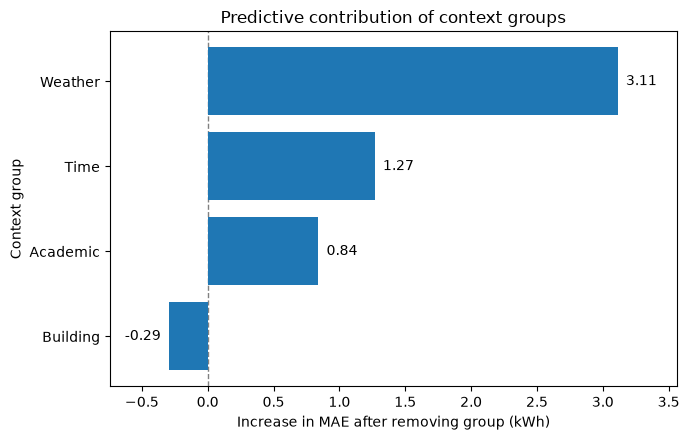

In [18]:
contribution = ablation.rename_axis("Context group").reset_index()
contribution["Context group"] = contribution["Context group"].replace({"Opening status": "Building"})
contribution = contribution.sort_values("Delta MAE", ascending=True)

plt.figure(figsize=(7, 4.5))
bars = plt.barh(contribution["Context group"], contribution["Delta MAE"], zorder=2)

# Subtiele verticale lijn bij 0, achter de balken
plt.axvline(0, color="gray", linestyle="--", linewidth=1, zorder=0)
plt.xlabel("Increase in MAE after removing group (kWh)")
plt.ylabel("Context group")
plt.title("Predictive contribution of context groups")

# Extra ruimte links en rechts voor de labels
xmin = contribution["Delta MAE"].min() - 0.45
xmax = contribution["Delta MAE"].max() + 0.45
plt.xlim(xmin, xmax)

# Waarden netjes aan het uiteinde van iedere balk
for bar, value in zip(bars, contribution["Delta MAE"]):
    y = bar.get_y() + bar.get_height() / 2
    if value >= 0:
        plt.annotate(f"{value:.2f}", xy=(value, y), xytext=(6, 0), textcoords="offset points", va="center", ha="left")
    else:
        plt.annotate(f"{value:.2f}", xy=(value, y), xytext=(-6, 0), textcoords="offset points", va="center", ha="right")

plt.tight_layout()
plt.savefig(figure_folder / "block7_context_contribution.png", dpi=300, bbox_inches="tight")
plt.show()



### Interpretation of grouped ablation
Read the ΔMAE values from the table and plot above. The largest positive value identifies the group whose removal worsens MAE the most in this setup. A negative value means removing the group improves test MAE. This is predictive contribution on one fixed holdout, not causal importance; the main model and success criterion are not changed after inspecting these results.

## 9. Residual and large-deviation analysis
Reuse the stored contextual predictions. Calculate **residual = actual − prediction** and **absolute_residual = abs(residual)**, then rank test hours by absolute residual. Positive residuals mean underprediction; negative ones mean overprediction.

Show residuals over the test period and a ±24-hour window around the largest error, clipped to the test period. This flags hours for investigation; it is not a calibrated anomaly detector and does not prove waste, faults or inefficiency.

**LLM support:** practical help rotating timestamp labels to reduce overlap.

In [19]:
results["residual"] = results[target] - results["contextual_prediction"]
results["absolute_residual"] = results["residual"].abs()
top_10 = results.nlargest(10, "absolute_residual")
display(top_10.round({
    "electricity_previous_day_same_hour": 3,
    "contextual_prediction": 3,
    "residual": 3,
    "absolute_residual": 3
}))
largest = results.loc[results["absolute_residual"].idxmax()]
largest_time = largest["timestamp"]


,timestamp,electricity_kWh,electricity_previous_day_same_hour,contextual_prediction,residual,absolute_residual
7170,2026-06-26 21:00:00,250,176.0,90.521,159.479,159.479
7191,2026-06-27 18:00:00,250,183.0,100.284,149.716,149.716
7192,2026-06-27 19:00:00,225,192.0,94.912,130.088,130.088
7187,2026-06-27 14:00:00,244,187.0,116.059,127.941,127.941
7186,2026-06-27 13:00:00,239,186.0,111.445,127.555,127.555
7161,2026-06-26 12:00:00,249,233.0,127.711,121.289,121.289
7184,2026-06-27 11:00:00,219,221.0,105.838,113.162,113.162
7193,2026-06-27 20:00:00,184,185.0,71.948,112.052,112.052
7171,2026-06-26 22:00:00,185,127.0,73.188,111.812,111.812
7144,2026-06-25 19:00:00,227,205.0,115.613,111.387,111.387


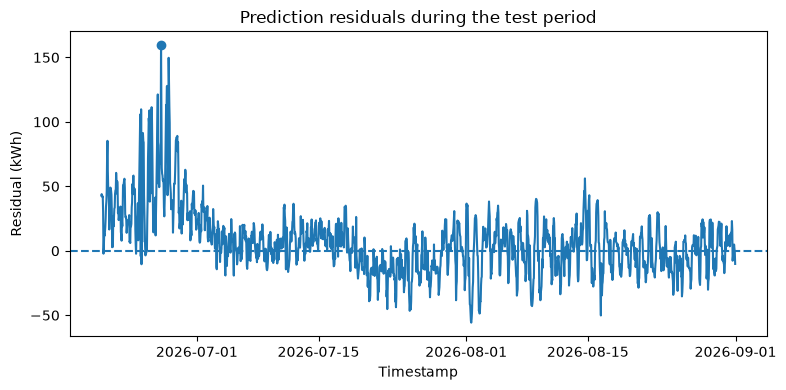

In [20]:
plt.figure(figsize=(8, 4))
plt.plot(results["timestamp"], results["residual"])
plt.axhline(0, linestyle="--")
plt.scatter(largest_time, largest["residual"], zorder=3)
plt.xlabel("Timestamp")
plt.ylabel("Residual (kWh)")
plt.title("Prediction residuals during the test period")
plt.tight_layout()
plt.savefig(figure_folder / "block8_test_residuals.png", dpi=300, bbox_inches="tight")
plt.show()


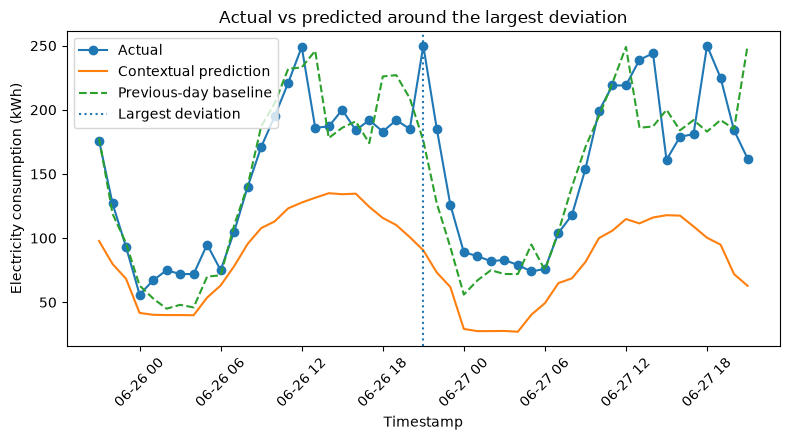

In [21]:
start = largest_time - pd.Timedelta(hours=24)
end = largest_time + pd.Timedelta(hours=24)
window = results[(results["timestamp"] >= start) & (results["timestamp"] <= end)].copy()

plt.figure(figsize=(8, 4.5))
plt.plot(window["timestamp"], window["electricity_kWh"], marker="o", label="Actual")
plt.plot(window["timestamp"], window["contextual_prediction"], label="Contextual prediction")
plt.plot(
    window["timestamp"],
    window["electricity_previous_day_same_hour"],
    linestyle="--",
    label="Previous-day baseline"
)
plt.axvline(largest_time, linestyle=":", label="Largest deviation")
plt.xlabel("Timestamp")
plt.ylabel("Electricity consumption (kWh)")
plt.title("Actual vs predicted around the largest deviation")
plt.xticks(rotation=45)
plt.legend()
plt.tight_layout()
plt.savefig(figure_folder / "block8_largest_deviation_window.png", dpi=300, bbox_inches="tight")
plt.show()


### Interpretation of the largest deviation
The top-ten table identifies the largest error and its timestamp; the window shows whether it is isolated or part of a broader pattern. Positive residuals mean underprediction. Selection follows absolute error across all contextual test predictions. Events, occupancy or equipment records would be needed to explain the cause.

## 10. Limitations
- One building, one year and one chronological holdout limit generalisation.
- `building_open` follows a simplified schedule, not observed occupancy. The `UT_closed` override is an assumption; exam/holiday opening exceptions are not reconstructed.
- `summer_period` and `outside_calendar` are absent from training and cover 1,368 of 1,752 test hours. The encoder handles them, but the model cannot learn a separate effect for those categories.
- Linear regression can miss nonlinear relationships and interactions.
- Observed weather and a rolling previous-day benchmark do not establish performance for an advance forecast of the entire test period.
- Ablation does not establish causality; residuals do not prove inefficiency or faults.
- The original assessment_period coding omits 7–10 April 2026 and uses the original summer ranges. This known calendar limitation is retained to preserve the original dataset.

### Link with data preparation
`Vrijhof_Data_Preparation.ipynb` documents the source data, timestamp handling and context-variable rules, and writes the `final_dataset.csv` used here. Rerun preparation before analysis if those rules change. The overall conclusion is discussed on the poster; use the current tables and figures for its numerical claims.